In [ ]:

%pip install -q "transformers>=4.45,<5" "datasets>=3.0" accelerate gradio pymupdf scikit-learn pandas matplotlib

import re, os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
import fitz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import pipeline

warnings.filterwarnings("ignore")

MODEL_NAME = "deepset/roberta-base-squad2"
qa = pipeline("question-answering", model=MODEL_NAME, tokenizer=MODEL_NAME)

sample_document = """
A Generative Adversarial Network, or GAN, contains two neural networks called the generator and discriminator.
The generator creates synthetic examples from random noise. The discriminator examines an example and predicts
whether it came from real training data or was generated by the generator.
A Transformer uses attention mechanisms to model relationships between tokens.
Self-attention lets each token use information from other tokens.
RoBERTa is a Transformer-based language model derived from BERT.
Extractive question answering predicts the start and end positions of an answer in a passage.
TF-IDF represents text using term frequency and inverse document frequency.
Cosine similarity compares text vectors to find relevant passages.
A limitation of extractive question answering is that it may select an incorrect answer when the passage is unclear.
"""

document_text = sample_document
document_name = "Built-in sample document"

def clean_text(text):
    return re.sub(r"\s+", " ", text).strip()

def split_into_chunks(text, chunk_words=140, overlap_words=30):
    words = clean_text(text).split()
    if not words:
        return []
    chunks = []
    step = max(1, chunk_words - overlap_words)
    for start in range(0, len(words), step):
        chunks.append(" ".join(words[start:start + chunk_words]))
        if start + chunk_words >= len(words):
            break
    return chunks

chunks = split_into_chunks(document_text)

vectorizer = TfidfVectorizer(stop_words="english")
chunk_matrix = vectorizer.fit_transform(chunks)

def retrieve_passages(question, top_k=3):
    scores = cosine_similarity(
        vectorizer.transform([question]), chunk_matrix
    ).ravel()
    order = np.argsort(scores)[::-1][:min(top_k, len(chunks))]
    return [(chunks[i], float(scores[i])) for i in order]

def answer_question(question, top_k=3, min_answer_score=0.05):
    question = question.strip()
    if not question:
        return {
            "question": question, "answer": "Please enter a question.",
            "answer_score": 0.0, "retrieval_score": 0.0,
            "source": "", "status": "empty_question"
        }

    candidates = []
    for passage, retrieval_score in retrieve_passages(question, top_k):
        result = qa(question=question, context=passage)
        candidates.append({
            "answer": result.get("answer", "").strip(),
            "answer_score": float(result.get("score", 0)),
            "retrieval_score": retrieval_score,
            "source": passage
        })

    best = max(candidates, key=lambda x: (x["answer_score"], x["retrieval_score"]))
    answer = best["answer"]
    status = "answered"

    if not answer or best["answer_score"] < min_answer_score:
        answer = "I could not find a sufficiently supported answer."
        status = "low_confidence"

    return {
        "question": question,
        "answer": answer,
        "answer_score": best["answer_score"],
        "retrieval_score": best["retrieval_score"],
        "source": best["source"],
        "status": status
    }

def ask(question):
    result = answer_question(question)
    print("Question:", result["question"])
    print("Answer:", result["answer"])
    print("Supporting passage:", result["source"])
    print("Model score:", round(result["answer_score"], 4))
    print("Retrieval similarity:", round(result["retrieval_score"], 4))
    return result

print("RoBERTa QA chatbot is ready!")
ask("What are the two neural networks in a GAN?")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/496M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

Device set to use cpu


RoBERTa QA chatbot is ready!
Question: What are the two neural networks in a GAN?
Answer: generator and discriminator
Supporting passage: A Generative Adversarial Network, or GAN, contains two neural networks called the generator and discriminator. The generator creates synthetic examples from random noise. The discriminator examines an example and predicts whether it came from real training data or was generated by the generator. A Transformer uses attention mechanisms to model relationships between tokens. Self-attention lets each token use information from other tokens. RoBERTa is a Transformer-based language model derived from BERT. Extractive question answering predicts the start and end positions of an answer in a passage. TF-IDF represents text using term frequency and inverse document frequency. Cosine similarity compares text vectors to find relevant passages. A limitation of extractive question answering is that it may select an incorrect answer when the passage is unclear.
M

{'question': 'What are the two neural networks in a GAN?',
 'answer': 'generator and discriminator',
 'answer_score': 0.6066576242446899,
 'retrieval_score': 0.1622214211307625,
 'source': 'A Generative Adversarial Network, or GAN, contains two neural networks called the generator and discriminator. The generator creates synthetic examples from random noise. The discriminator examines an example and predicts whether it came from real training data or was generated by the generator. A Transformer uses attention mechanisms to model relationships between tokens. Self-attention lets each token use information from other tokens. RoBERTa is a Transformer-based language model derived from BERT. Extractive question answering predicts the start and end positions of an answer in a passage. TF-IDF represents text using term frequency and inverse document frequency. Cosine similarity compares text vectors to find relevant passages. A limitation of extractive question answering is that it may selec

,Question,Reference,Prediction,Exact Match,Token F1,Model Score,Retrieval Score
0,What are the two neural networks in a GAN?,generator and discriminator,generator and discriminator,1,1.000000,0.606658,0.162221
1,What mechanism does a Transformer use?,attention mechanisms,attention,0,0.666667,0.602398,0.198680
2,What does TF-IDF represent?,term frequency and inverse document frequency,text,0,0.000000,0.449177,0.132453
3,What is RoBERTa?,a Transformer-based language model,a Transformer-based language model derived fro...,0,0.769231,0.325335,0.093659


Mean Exact Match: 0.25
Mean Token F1: 0.609


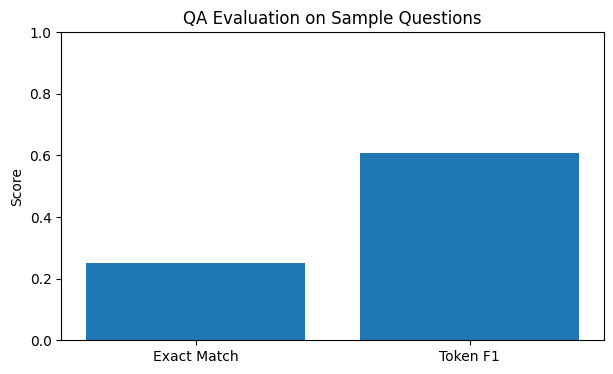

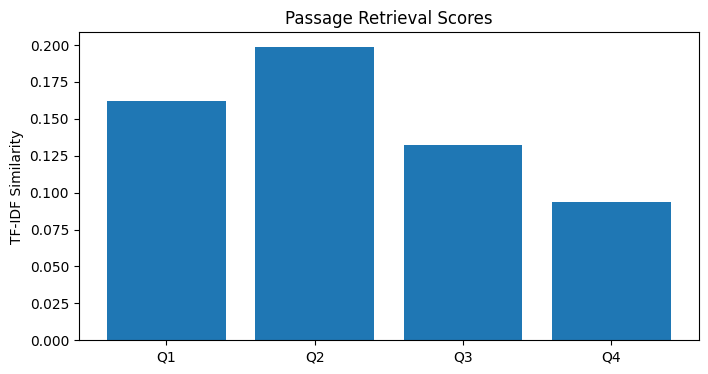

In [ ]:

import string
from collections import Counter

def normalize_answer(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    return " ".join(text.split())

def exact_match(prediction, reference):
    return int(normalize_answer(prediction) == normalize_answer(reference))

def token_f1(prediction, reference):
    p = normalize_answer(prediction).split()
    r = normalize_answer(reference).split()

    if not p or not r:
        return float(p == r)

    overlap = sum((Counter(p) & Counter(r)).values())
    if overlap == 0:
        return 0.0

    precision = overlap / len(p)
    recall = overlap / len(r)
    return 2 * precision * recall / (precision + recall)

evaluation_examples = [
    ("What are the two neural networks in a GAN?", "generator and discriminator"),
    ("What mechanism does a Transformer use?", "attention mechanisms"),
    ("What does TF-IDF represent?", "term frequency and inverse document frequency"),
    ("What is RoBERTa?", "a Transformer-based language model")
]

rows = []

for question, reference in evaluation_examples:
    result = answer_question(question)
    rows.append({
        "Question": question,
        "Reference": reference,
        "Prediction": result["answer"],
        "Exact Match": exact_match(result["answer"], reference),
        "Token F1": token_f1(result["answer"], reference),
        "Model Score": result["answer_score"],
        "Retrieval Score": result["retrieval_score"]
    })

evaluation_df = pd.DataFrame(rows)
display(evaluation_df)

print("Mean Exact Match:", round(evaluation_df["Exact Match"].mean(), 3))
print("Mean Token F1:", round(evaluation_df["Token F1"].mean(), 3))

plt.figure(figsize=(7, 4))
plt.bar(
    ["Exact Match", "Token F1"],
    [evaluation_df["Exact Match"].mean(), evaluation_df["Token F1"].mean()]
)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("QA Evaluation on Sample Questions")
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(
    [f"Q{i+1}" for i in range(len(evaluation_df))],
    evaluation_df["Retrieval Score"]
)
plt.ylabel("TF-IDF Similarity")
plt.title("Passage Retrieval Scores")
plt.show()


README.md: 0.00B [00:00, ?B/s]

squad_v2/train-00000-of-00001.parquet:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

squad_v2/validation-00000-of-00001.parqu(…):   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,1.297000,0.716845


Evaluation: {'eval_loss': 0.716844916343689, 'eval_runtime': 35.9409, 'eval_samples_per_second': 0.835, 'eval_steps_per_second': 0.417, 'epoch': 1.0}


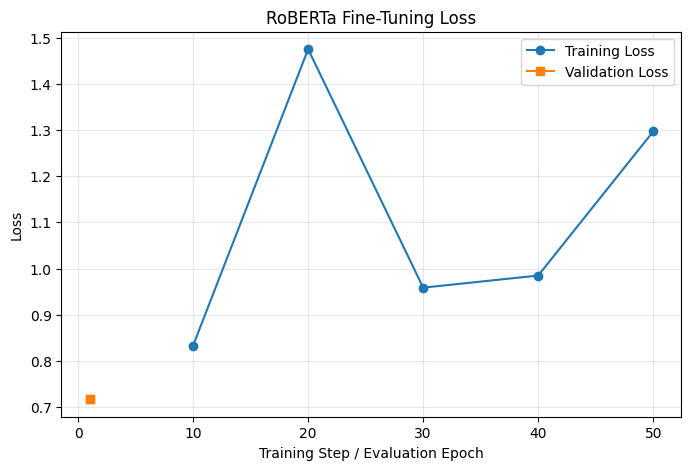

Fine-tuned model saved.


In [ ]:

import inspect
import torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForQuestionAnswering,
    TrainingArguments, Trainer, default_data_collator
)

MODEL_NAME = "deepset/roberta-base-squad2"
tokenizer_ft = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
model_ft = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME)

data = load_dataset("squad_v2")
train_data = data["train"].shuffle(seed=42).select(range(100))
valid_data = data["validation"].shuffle(seed=42).select(range(30))

MAX_LENGTH = 384

def prepare_features(examples):
    encoded = tokenizer_ft(
        [q.strip() for q in examples["question"]],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LENGTH,
        padding="max_length",
        return_offsets_mapping=True
    )

    starts, ends = [], []

    for i, answers in enumerate(examples["answers"]):
        offsets = encoded["offset_mapping"][i]
        sequence_ids = encoded.sequence_ids(i)

        context_ids = [
            j for j, sid in enumerate(sequence_ids) if sid == 1
        ]

        cls_index = encoded["input_ids"][i].index(tokenizer_ft.cls_token_id)

        if not answers["text"] or not context_ids:
            starts.append(cls_index)
            ends.append(cls_index)
            continue

        start_char = answers["answer_start"][0]
        end_char = start_char + len(answers["text"][0])
        first, last = context_ids[0], context_ids[-1]

        if offsets[first][0] > start_char or offsets[last][1] < end_char:
            starts.append(cls_index)
            ends.append(cls_index)
            continue

        token_start = first
        while token_start <= last and offsets[token_start][0] <= start_char:
            token_start += 1
        token_start -= 1

        token_end = last
        while token_end >= first and offsets[token_end][1] >= end_char:
            token_end -= 1
        token_end += 1

        starts.append(token_start)
        ends.append(token_end)

    encoded.pop("offset_mapping")
    encoded["start_positions"] = starts
    encoded["end_positions"] = ends
    return encoded

train_features = train_data.map(
    prepare_features, batched=True,
    remove_columns=train_data.column_names
)

valid_features = valid_data.map(
    prepare_features, batched=True,
    remove_columns=valid_data.column_names
)

args_kwargs = dict(
    output_dir="/content/roberta_qa_finetuned",
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    num_train_epochs=1,
    weight_decay=0.01,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available()
)

if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters:
    args_kwargs["eval_strategy"] = "epoch"
else:
    args_kwargs["evaluation_strategy"] = "epoch"

training_args = TrainingArguments(**args_kwargs)

trainer = Trainer(
    model=model_ft,
    args=training_args,
    train_dataset=train_features,
    eval_dataset=valid_features,
    data_collator=default_data_collator
)

trainer.train()
print("Evaluation:", trainer.evaluate())

history = trainer.state.log_history
train_points = [
    (x["step"], x["loss"]) for x in history
    if "loss" in x and "eval_loss" not in x
]
eval_points = [
    (x.get("epoch", x.get("step", i)), x["eval_loss"])
    for i, x in enumerate(history) if "eval_loss" in x
]

plt.figure(figsize=(8, 5))
if train_points:
    plt.plot(
        [x[0] for x in train_points],
        [x[1] for x in train_points],
        marker="o", label="Training Loss"
    )
if eval_points:
    plt.plot(
        [x[0] for x in eval_points],
        [x[1] for x in eval_points],
        marker="s", label="Validation Loss"
    )
plt.xlabel("Training Step / Evaluation Epoch")
plt.ylabel("Loss")
plt.title("RoBERTa Fine-Tuning Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

trainer.save_model("/content/roberta_qa_finetuned")
tokenizer_ft.save_pretrained("/content/roberta_qa_finetuned")
print("Fine-tuned model saved.")


In [ ]:

import gradio as gr

def chatbot_response(question):
    result = answer_question(question)
    return (
        result["answer"],
        result["source"],
        f"Model score: {result['answer_score']:.4f}; "
        f"retrieval similarity: {result['retrieval_score']:.4f}"
    )

demo = gr.Interface(
    fn=chatbot_response,
    inputs=gr.Textbox(lines=2, label="Ask a question"),
    outputs=[
        gr.Textbox(label="Answer"),
        gr.Textbox(label="Supporting passage"),
        gr.Textbox(label="Scores")
    ],
    title="Closed-Domain Technical Documentation QA Bot"
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cb7ee85f424bf18336.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
